In [1]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.append('..')

import numpy as np
import matplotlib.pyplot as plt
import fastf1
import pandas as pd

from src.track import track_geometry

fastf1.Cache.enable_cache('../cache')
fastf1.set_log_level('WARNING')

c:\Users\Ryan\Documents\f1-lapsim\.venv\Lib\site-packages\fastf1\req.py:251: FutureWarning: `.enable_cache` is deprecated and will be removed in a future version. Use `.configure` instead.
  warnings.warn("`.enable_cache` is deprecated and will be removed in a "


In [2]:
session = fastf1.get_session(2022, 'Spain', 'Q')
session.load()
lap = session.laps.pick_fastest()

geo = track_geometry(lap)

print(lap['Driver'], lap['LapTime'], lap['Compound'])
print(f"{len(geo)} points, lap length {geo['s'].iloc[-1]:.0f} m")
geo.head()

LEC 0 days 00:01:18.750000 SOFT
2293 points, lap length 4584 m


,s,x,y,kappa,r,v,a_lat_g
0,0.0,75.828888,-57.340361,-0.000003,10000.0,80.065973,0.002083
1,2.0,74.687709,-59.145544,-0.000007,10000.0,80.128024,0.004814
2,4.0,73.550211,-60.944850,-0.000017,10000.0,80.190074,0.011110
3,6.0,72.418878,-62.734263,-0.000028,10000.0,80.252125,0.018521
4,8.0,71.295489,-64.510877,-0.000040,10000.0,80.314175,0.026435


In [3]:
# =================================
# Getting density from the weather
# =================================

weather = lap.get_weather_data()      

T_air = weather['AirTemp'] + 273.15    
p_air = weather['Pressure'] * 100      
R_air = 287.05                         

rho = p_air / (R_air * T_air)          

print(f"Air {weather['AirTemp']:.1f} °C, {weather['Pressure']:.1f} mbar, "
      f"humidity {weather['Humidity']:.0f} %")
print(f"rho = {rho:.3f} kg/m^3")

Air 34.6 °C, 1002.9 mbar, humidity 18 %
rho = 1.135 kg/m^3


Hot qualifying session, it is about 7% below ISA

In [4]:
# =================================
# Deriving ClA from the Mercedes statements
# =================================

G = 9.81
m_ref   = 795.0     
rho_ref = 1.225     # Assumed ISA 

# =================================
# Statement 1: downforce = weight at ~150 km/h
# =================================
 
v_eq = 150 / 3.6
ClA_low_speed = m_ref * G / (0.5 * rho_ref * v_eq**2)

# =================================
# Statement 2: 3–4x weight at max speed 
# assumed that v_max = 320 km/h
# =================================

v_max = 320 / 3.6
ClA_3x = 3 * m_ref * G / (0.5 * rho_ref * v_max**2)
ClA_4x = 4 * m_ref * G / (0.5 * rho_ref * v_max**2)

print(f"ClA from 'weight at 150 km/h': {ClA_low_speed:.2f} m^2")
print(f"ClA from '3-4x at 320 km/h'  : {ClA_3x:.2f} – {ClA_4x:.2f} m^2")

ClA from 'weight at 150 km/h': 7.33 m^2
ClA from '3-4x at 320 km/h'  : 4.83 – 6.45 m^2


In [5]:
# =================================
# Sanity check on the radius
# =================================

from src.params import CAR_2022, RANGES_2022
from src.vehicle import v_apex, critical_radius

car = CAR_2022
r_crit = critical_radius(car['m'], car['mu_y'], rho, car['ClA'])
print(f"r_crit = {r_crit:.0f} m\n")

r_test = np.array([21.3, 50.0, 100.0, 140.0, 200.0])
v_aero = v_apex(r_test, car['m'], car['mu_y'], rho, car['ClA'])
v_noaero = np.sqrt(car['mu_y'] * G * r_test)

for r_i, va, vn in zip(r_test, v_aero, v_noaero):
    print(f"r = {r_i:6.1f} m   v_apex = {va*3.6:6.1f} km/h   "
          f"no-aero = {vn*3.6:6.1f} km/h   ratio = {va/vn:5.2f}")

r_crit = 146 m

r =   21.3 m   v_apex =   71.2 km/h   no-aero =   65.8 km/h   ratio =  1.08
r =   50.0 m   v_apex =  124.4 km/h   no-aero =  100.9 km/h   ratio =  1.23
r =  100.0 m   v_apex =  254.4 km/h   no-aero =  142.6 km/h   ratio =  1.78
r =  140.0 m   v_apex =  843.0 km/h   no-aero =  168.8 km/h   ratio =  5.00
r =  200.0 m   v_apex =    inf km/h   no-aero =  201.7 km/h   ratio =   inf


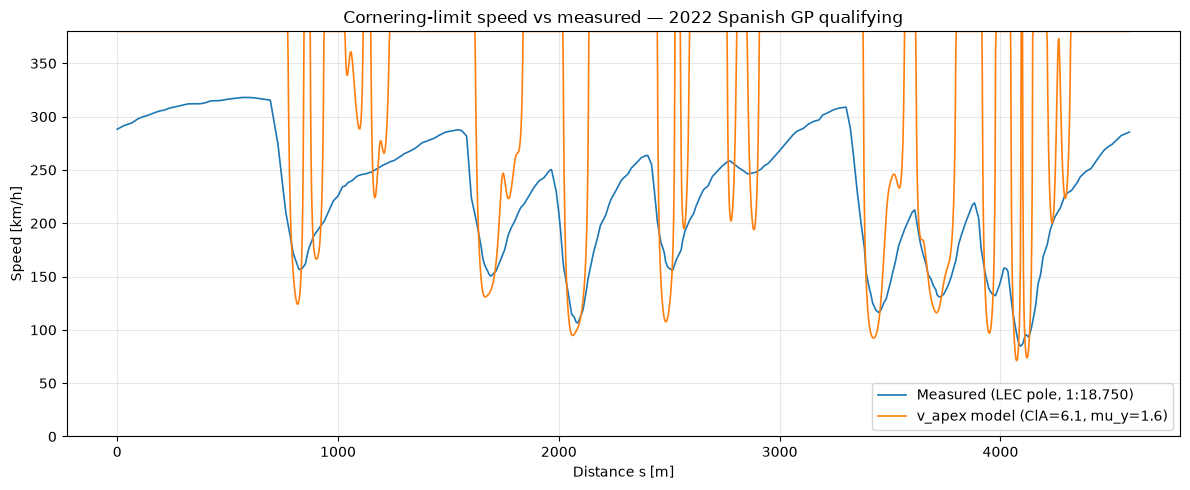

Points where measured > v_apex: 294 of 2293


In [6]:
# =================================
# The full lap against measured speed
# =================================

geo['v_apex'] = v_apex(geo['r'], car['m'], car['mu_y'], rho, car['ClA'])

v_plot_cap = 380 / 3.6   # display only: draw 'no limit' at top of axes

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(geo['s'], geo['v'] * 3.6, lw=1.2, label='Measured (LEC pole, 1:18.750)')
ax.plot(geo['s'], np.minimum(geo['v_apex'], v_plot_cap) * 3.6,
        lw=1.2, label=f'v_apex model (ClA={car["ClA"]}, mu_y={car["mu_y"]})')
ax.set_ylim(0, 380)
ax.set_xlabel('Distance s [m]')
ax.set_ylabel('Speed [km/h]')
ax.set_title('Cornering-limit speed vs measured — 2022 Spanish GP qualifying')
ax.grid(alpha=0.3)
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig('../figures/03_vapex_vs_measured.png', dpi=200)
plt.show()

n_over = (geo['v'] > geo['v_apex']).sum()
print(f"Points where measured > v_apex: {n_over} of {len(geo)}")

In [7]:
# =================================
# A pre corner diagnosis
# =================================

from scipy.signal import find_peaks

v = geo['v'].to_numpy()                          # measured speed [m/s]
idx, _ = find_peaks(-v, prominence=20/3.6)       # minima at least 20 km/h deep

half = 10                                        # ±10 samples = ±20 m at ds = 2 m
rows = []
for i in idx:
    win = slice(max(i - half, 0), i + half + 1)  # samples around this apex
    r_min = geo['r'].iloc[win].min()
    v_meas = v[i]
    v_mod = geo['v_apex'].iloc[win].min()
    a_lat = v_meas**2 / r_min
    mu_req = a_lat / (G + 0.5 * rho * v_meas**2 * car['ClA'] / car['m'])
    rows.append({'s': geo['s'].iloc[i], 'r_min': r_min,
                 'v_meas_kmh': v_meas * 3.6, 'v_apex_kmh': v_mod * 3.6,
                 'a_lat_g': a_lat / G, 'mu_req': mu_req})

apex_table = pd.DataFrame(rows).round(2)
apex_table

,s,r_min,v_meas_kmh,v_apex_kmh,a_lat_g,mu_req
0,824.0,49.84,156.69,124.11,3.87,2.12
1,1692.0,53.64,150.46,131.38,3.32,1.88
2,2084.0,33.92,106.43,94.81,2.63,1.90
3,2514.0,43.65,155.70,112.57,4.37,2.40
4,3448.0,32.65,116.53,92.50,3.27,2.24
5,3724.0,45.58,131.00,116.13,2.96,1.88
6,3976.0,37.44,132.19,101.23,3.67,2.31
7,4092.0,21.26,84.79,71.16,2.66,2.14


In [8]:
# =================================
# Turning the above "Apex Table" into a function
# =================================

def apex_table(geo, rho, car, prominence_kmh=20.0, half=10):
    """Per-corner apex diagnostics from a track_geometry DataFrame.

    geo must already contain a 'v_apex' column. Apexes are located from
    minima of the MEASURED speed. mu_req is the friction coefficient
    needed to explain the measured apex speed, given car['ClA'].
    """
    v = geo['v'].to_numpy()
    idx, _ = find_peaks(-v, prominence=prominence_kmh / 3.6)

    rows = []
    for i in idx:
        win = slice(max(i - half, 0), i + half + 1)
        r_min = geo['r'].iloc[win].min()
        v_meas = v[i]
        a_lat = v_meas**2 / r_min
        rows.append({
            's': geo['s'].iloc[i],
            'r_min': r_min,
            'v_meas_kmh': v_meas * 3.6,
            'v_apex_kmh': geo['v_apex'].iloc[win].min() * 3.6,
            'v2': v_meas**2,
            'a_lat': a_lat,
            'a_lat_g': a_lat / G,
            'mu_req': a_lat / (G + 0.5 * rho * v_meas**2 * car['ClA'] / car['m']),
        })
    return pd.DataFrame(rows)

In [9]:
# =================================
# Running the function at low 
# prominence to catch fast corners
# =================================

apex_lec = apex_table(geo, rho, car, prominence_kmh=10)
apex_lec.round(2)

,s,r_min,v_meas_kmh,v_apex_kmh,v2,a_lat,a_lat_g,mu_req
0,824.0,49.84,156.69,124.11,1894.48,38.01,3.87,2.12
1,1692.0,53.64,150.46,131.38,1746.73,32.56,3.32,1.88
2,2084.0,33.92,106.43,94.81,874.04,25.77,2.63,1.90
3,2514.0,43.65,155.70,112.57,1870.65,42.85,4.37,2.40
4,2854.0,86.20,246.33,207.06,4681.80,54.32,5.54,1.82
5,3448.0,32.65,116.53,92.50,1047.85,32.10,3.27,2.24
6,3724.0,45.58,131.00,116.13,1324.15,29.05,2.96,1.88
7,3976.0,37.44,132.19,101.23,1348.38,36.01,3.67,2.31
8,4092.0,21.26,84.79,71.16,554.69,26.09,2.66,2.14


Corners used: 9
Intercept A = 23.34 ± 2.22 m/s^2  ->  mu_y  = 2.38 ± 0.23
Slope     B = 0.00696 ± 0.00108 1/m  ->  ClA = 4.16 m^2
(sourced: mu_y = 1.6, ClA = 6.1)


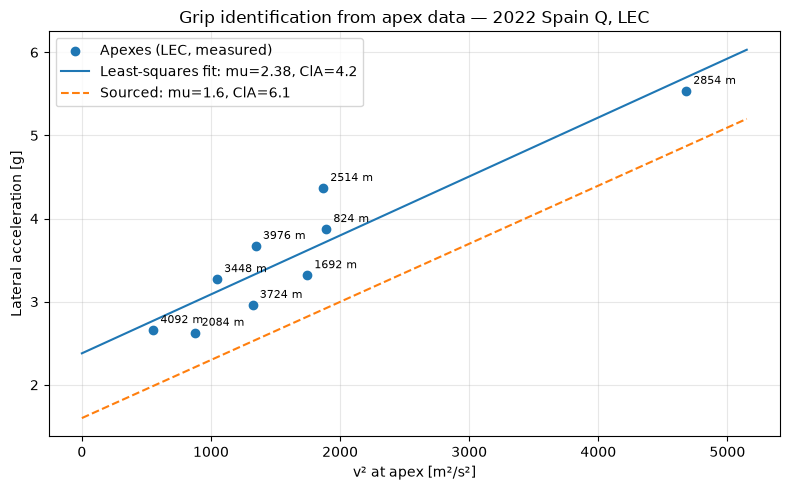

In [10]:
# =================================
# Fitting
# =================================

# =================================
# Least Squares (a_lat = A + B * v^2)
# Standard errors of B and A
# =================================

(B, A), cov = np.polyfit(apex_lec['v2'], apex_lec['a_lat'], 1, cov=True)
sB, sA = np.sqrt(np.diag(cov))   

mu_fit = A / G
ClA_fit = 2 * car['m'] * B / (rho * mu_fit)

print(f"Corners used: {len(apex_lec)}")
print(f"Intercept A = {A:.2f} ± {sA:.2f} m/s^2  ->  mu_y  = {mu_fit:.2f} ± {sA/G:.2f}")
print(f"Slope     B = {B:.5f} ± {sB:.5f} 1/m  ->  ClA = {ClA_fit:.2f} m^2")
print(f"(sourced: mu_y = {car['mu_y']}, ClA = {car['ClA']})")

# =================================
# Figure
# =================================

v2_line = np.linspace(0, apex_lec['v2'].max() * 1.1, 100)
k_src = rho * car['ClA'] / (2 * car['m'])

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(apex_lec['v2'], apex_lec['a_lat'] / G, zorder=3, label='Apexes (LEC, measured)')
ax.plot(v2_line, (A + B * v2_line) / G,
        label=f'Least-squares fit: mu={mu_fit:.2f}, ClA={ClA_fit:.1f}')
ax.plot(v2_line, car['mu_y'] * (G + k_src * v2_line) / G, '--',
        label=f'Sourced: mu={car["mu_y"]}, ClA={car["ClA"]}')
for _, row in apex_lec.iterrows():
    ax.annotate(f"{row['s']:.0f} m", (row['v2'], row['a_lat'] / G),
                textcoords='offset points', xytext=(5, 5), fontsize=8)
ax.set_xlabel('v² at apex [m²/s²]')
ax.set_ylabel('Lateral acceleration [g]')
ax.set_title('Grip identification from apex data — 2022 Spain Q, LEC')
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig('../figures/03_grip_identification.png', dpi=200)
plt.show()

In [11]:
# =================================
# Seeing how coupled the A and B estimates are
# =================================

corr_AB = cov[0, 1] / (sA * sB)

# =================================
# Sourced parameters in A and B form
# =================================

A_src = car['mu_y'] * G
B_src = car['mu_y'] * rho * car['ClA'] / (2 * car['m'])

print(f"Correlation between A and B estimates: {corr_AB:.2f}")
print(f"A: fitted {A:.1f} ± {sA:.1f}, sourced {A_src:.1f} m/s^2  "
      f"-> {(A - A_src)/sA:+.1f} sigma")
print(f"B: fitted {B:.5f} ± {sB:.5f}, sourced {B_src:.5f} 1/m  "
      f"-> {(B - B_src)/sB:+.1f} sigma")
print(f"r_crit: fitted {1/B:.0f} m, sourced {1/B_src:.0f} m\n")

# =================================
# Testing the leverage of Turn 9
# =================================

slow = apex_lec[apex_lec['v2'] < 3000]
(B2, A2), cov2 = np.polyfit(slow['v2'], slow['a_lat'], 1, cov=True)
sB2, sA2 = np.sqrt(np.diag(cov2))
print(f"Without T9 ({len(slow)} corners): A = {A2:.1f} ± {sA2:.1f} m/s^2, "
      f"B = {B2:.5f} ± {sB2:.5f} 1/m")

Correlation between A and B estimates: -0.83
A: fitted 23.3 ± 2.2, sourced 15.7 m/s^2  -> +3.4 sigma
B: fitted 0.00696 ± 0.00108, sourced 0.00686 1/m  -> +0.1 sigma
r_crit: fitted 144 m, sourced 146 m

Without T9 (8 corners): A = 19.3 ± 3.9 m/s^2, B = 0.01014 ± 0.00274 1/m


In [12]:
# =================================
# Validating on a different driver
# =================================

lap_ver = session.laps.pick_drivers('VER').pick_fastest()
geo_ver = track_geometry(lap_ver)

w = lap_ver.get_weather_data()
rho_ver = (w['Pressure'] * 100) / (R_air * (w['AirTemp'] + 273.15))
print(lap_ver['Driver'], lap_ver['LapTime'], f"rho = {rho_ver:.3f}")

def apex_errors(mu, ClA, label):
    """Apex table for VER's lap with v_apex computed from the given mu, ClA."""
    geo_ver['v_apex'] = v_apex(geo_ver['r'], car['m'], mu, rho_ver, ClA)
    t = apex_table(geo_ver, rho_ver, car, prominence_kmh=10)
    t = t[t['r_min'] < 500].reset_index(drop=True)
    err = t['v_apex_kmh'] - t['v_meas_kmh']
    print(f"{label:8s}: {len(t)} corners, mean error {err.mean():+6.1f} km/h, "
          f"RMS {np.sqrt((err**2).mean()):5.1f} km/h")
    return t.assign(err_kmh=err)

ver_src = apex_errors(car['mu_y'], car['ClA'], 'Sourced')
ver_fit = apex_errors(mu_fit, ClA_fit, 'Fitted')
ver_fit[['s', 'r_min', 'v_meas_kmh', 'v_apex_kmh', 'err_kmh']].round(1)

VER 0 days 00:01:19.073000 rho = 1.136
Sourced : 8 corners, mean error  -21.5 km/h, RMS  25.8 km/h
Fitted  : 8 corners, mean error   +2.3 km/h, RMS  14.9 km/h


,s,r_min,v_meas_kmh,v_apex_kmh,err_kmh
0,822.0,50.1,152.1,152.5,0.4
1,1694.0,57.3,149.3,169.7,20.4
2,2082.0,35.1,102.5,118.5,16.0
3,2502.0,41.7,156.1,133.3,-22.8
4,3454.0,36.2,114.2,121.0,6.9
5,3716.0,44.9,128.2,140.5,12.3
6,3964.0,35.3,138.1,118.9,-19.2
7,4084.0,21.2,82.6,86.8,4.2


In [13]:
# =================================
# Corner by corner consistency between drivers
# =================================

lec = apex_lec[['s', 'mu_req']].rename(columns={'mu_req': 'mu_req_lec'})
both = pd.merge_asof(ver_fit.sort_values('s'), lec.sort_values('s'),
                     on='s', direction='nearest', tolerance=30).dropna()

rho_corr = np.corrcoef(both['mu_req_lec'], both['err_kmh'])[0, 1]
print(f"Matched corners: {len(both)}")
print(f"Correlation (LEC mu_req vs VER fitted-model error): {rho_corr:.2f}")

Matched corners: 8
Correlation (LEC mu_req vs VER fitted-model error): -0.90


In [ ]:
# =================================
# Sensitivity
# =================================

base = dict(m=car['m'], mu_y=car['mu_y'], rho=rho, ClA=car['ClA'])
corners = {'Chicane': 21.3, 'T9': 86.2}

for name, r0 in corners.items():
    v0 = float(v_apex(r0, **base)) * 3.6
    print(f"\n{name} (r = {r0} m): baseline v_apex = {v0:.1f} km/h")
    for p, (lo, hi) in RANGES_2022.items():
        if p not in base:
            continue
        v_lo = float(v_apex(r0, **{**base, p: lo})) * 3.6
        v_hi = float(v_apex(r0, **{**base, p: hi})) * 3.6
        print(f"  {p:5s} {lo:>6} to {hi:<6}: {v_lo:6.1f} to {v_hi:6.1f} km/h")

v_r = v_apex(np.array([17.0, 26.0]), **base) * 3.6
print(f"\nChicane radius 17 to 26 m (Stage 2 filter range): {v_r[0]:.1f} to {v_r[1]:.1f} km/h")


Chicane (r = 21.3 m): baseline v_apex = 71.2 km/h
  m      803.0 to 818.0 :   71.3 to   71.2 km/h
  ClA      4.8 to 7.3   :   70.0 to   72.5 km/h
  mu_y     1.4 to 1.8   :   65.9 to   76.4 km/h

T9 (r = 86.2 m): baseline v_apex = 207.1 km/h
  m      803.0 to 818.0 :  208.0 to  205.3 km/h
  ClA      4.8 to 7.3   :  181.1 to  244.8 km/h
  mu_y     1.4 to 1.8   :  178.3 to  242.6 km/h

Chicane radius 17 to 26 m (Stage 2 filter range): 62.6 to 80.2 km/h
